# 25. The reliability layer and the conditioning error in its specification

Four notebooks tried to fix the early inner-race call with better features: hesitation (nb15, nb17), distance (nb15), resonance and spectral shape (nb18), and shaft-synchronous modulation (nb20). The next-steps section of notebook 20 drew the conclusion and named the only route left. It said to retire the early inner-race error as a feature-engineering problem and to change the question instead of the feature. Notebook 17 had shown that the system's output is a per-element rate, so an explanation layer could say "inner-race calls in the first fifth after an alarm are wrong about 60 % of the time". That is deliverable today and needs no new signal processing.

This notebook builds that layer. Nothing new is computed from raw data. The stage-1 alarm and the stage-2 race model are rebuilt exactly as notebooks 14 and 15 built them, and the only addition is a reliability table: a rate attached to each call, estimated on training units and validated on a held-out one.

The sentence quoted above cannot be said, and the reason is structural, not statistical. It conditions on which element the bearing actually has. A deployed system conditions on which element it just called, which is all an engineer holds at the moment the sentence would be spoken. The two conditionings do not describe the same snapshots, and on this data they do not point at the same class either.

Everything is nested. For a held-out unit h, the reliability table is built from predictions on the other ten units made by models that never saw h either, so 110 extra stage-2 fits stand behind the eleven tables. Two controls run alongside, following the standing rule from notebooks 20 and 21. A permuted key asks whether the table's key carries anything. A matched random key asks whether its structure alone would produce the same number.

In [1]:
import os
import pathlib
import warnings

# sklearn's joblib workers re-emit a UserWarning on every parallel fit; the filter
# has to reach the worker processes, so it goes in the environment as well (nb20)
os.environ["PYTHONWARNINGS"] = "ignore::UserWarning"
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from scipy.stats import beta

OUT = pathlib.Path("../data/processed")
ds = pd.read_csv(OUT / "xjtu_envelope_features.csv")     # built by notebook 13

FAULT = {"Bearing1_1": "OR", "Bearing1_2": "OR", "Bearing1_3": "OR",
         "Bearing1_4": "cage", "Bearing1_5": "IR+OR", "Bearing2_1": "IR",
         "Bearing2_2": "OR", "Bearing2_3": "cage", "Bearing2_4": "OR",
         "Bearing2_5": "OR", "Bearing3_1": "OR", "Bearing3_2": "compound",
         "Bearing3_3": "IR", "Bearing3_4": "IR", "Bearing3_5": "OR"}
BEAR = sorted(ds["Bearing"].unique())
RACE = [b for b in BEAR if FAULT[b] in ("OR", "IR")]
G = {b: ds[ds["Bearing"] == b].sort_values("Snapshot").reset_index(drop=True) for b in BEAR}

ENV = ["H_BPFO", "H_BPFI", "H_FR", "H_BPFO_h2", "H_BPFI_h2", "H_BSF", "H_FTF",
       "H_BPFI_sb1", "H_BPFO_sb1"]
DETECT = ["H_RMS", "H_Kurt"]
K, W = 20, 10
NB = 5                                    # phase bins; bin 0 is nb20's "first fifth"
RFC = dict(n_estimators=300, random_state=0, n_jobs=-1)
RNG = np.random.default_rng(0)


class Exceedance:
    '''Robust per-feature z over the unit's own healthy baseline (notebook 07).'''

    def fit(self, A):
        self.med = np.median(A, axis=0)
        self.mad = np.maximum(1.4826 * np.median(np.abs(A - self.med), axis=0), 0.1)
        return self

    def score(self, A):
        return ((A - self.med) / self.mad).max(axis=1)


ALARM = {}
for b in BEAR:                                           # notebook 14's stage-1 alarm
    A = G[b][DETECT].to_numpy()
    z = Exceedance().fit(A[:K]).score(A)
    c = np.convolve((z[K:] > np.quantile(z[:K], 0.99)).astype(float), np.ones(W) / W, "valid")
    ALARM[b] = int(np.flatnonzero(c >= 0.5)[0]) + K

RAW = {b: G[b][ENV].to_numpy() for b in BEAR}
POST = {b: (RAW[b] - np.median(RAW[b][:K], axis=0))[ALARM[b]:] for b in BEAR}


def fit_predict(train, target):
    '''Notebook 14's stage 2, keeping the confidence behind each call.'''
    clf = RandomForestClassifier(**RFC).fit(
        np.vstack([POST[o] for o in train]),
        np.concatenate([[FAULT[o]] * len(POST[o]) for o in train]))
    pr = clf.predict_proba(POST[target])
    return clf.classes_[pr.argmax(axis=1)], pr.max(axis=1)


OUTER = {h: fit_predict([o for o in RACE if o != h], h) for h in RACE}
# nested: what the table for held-out h may know about unit u (h is withheld too)
NESTED = {(h, u): fit_predict([o for o in RACE if o not in (h, u)], u)
          for h in RACE for u in RACE if u != h}


def long(preds, units, permute_phase=False):
    '''One row per post-alarm minute: the call, whether it was right, and its keys.

    `fbin` bins the share of post-alarm life already elapsed -- available only in
    hindsight, since it needs the failure time. `mbin` bins elapsed minutes, which
    is what a deployed system actually holds. `rbin` is the matched random key.
    '''
    rows = []
    for b in units:
        p, c = preds[b]
        n = len(p)
        fb = (np.arange(n) / n * NB).astype(int)
        rows.append(pd.DataFrame(dict(
            Bearing=b, truth=FAULT[b], pred=p, conf=c, ok=(p == FAULT[b]),
            fbin=RNG.permutation(fb) if permute_phase else fb,
            mbin=np.minimum(np.arange(n) // 10, NB - 1),
            rbin=RNG.integers(0, NB, n), mins=np.arange(n))))
    return pd.concat(rows, ignore_index=True)


T = long(OUTER, RACE)

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"                  # OR / IR, the only two classes
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
FCOLOR = {"OR": C_BLUE, "IR": C_ORANGE}

print(f"stage 2 rebuilt: {np.mean([(OUTER[b][0] == FAULT[b]).mean() for b in RACE]):.1%} "
      f"of snapshots, "
      f"{sum(pd.Series(OUTER[b][0]).mode()[0] == FAULT[b] for b in RACE)}/{len(RACE)} units"
      f"   (notebook 14: 94.1 %, 11/11)")
g, w = T.loc[T["ok"], "conf"], T.loc[~T["ok"], "conf"]
print(f"may-be-wrong flag rebuilt: "
      f"{roc_auc_score(np.r_[np.ones(len(g)), np.zeros(len(w))], np.r_[g, w]):.3f} AUROC"
      f"   (notebook 15: 0.752)")
print(f"nested tables: {len(NESTED)} extra stage-2 fits behind {len(RACE)} held-out units")

print("\npost-alarm window per unit -- the denominator of 'first fifth':")
for b in RACE:
    n = len(POST[b])
    print(f"  {b} ({FAULT[b]})  {n:4d} min   first fifth = {n // NB:3d} min")
L = np.array([len(POST[b]) for b in RACE])
print(f"  spread {L.min()}-{L.max()} min = {L.max() / L.min():.1f}x")

stage 2 rebuilt: 94.1% of snapshots, 11/11 units   (notebook 14: 94.1 %, 11/11)
may-be-wrong flag rebuilt: 0.752 AUROC   (notebook 15: 0.752)
nested tables: 110 extra stage-2 fits behind 11 held-out units

post-alarm window per unit -- the denominator of 'first fifth':
  Bearing1_1 (OR)   103 min   first fifth =  20 min
  Bearing1_2 (OR)   123 min   first fifth =  24 min
  Bearing1_3 (OR)   104 min   first fifth =  20 min
  Bearing2_1 (IR)    45 min   first fifth =   9 min
  Bearing2_2 (OR)   141 min   first fifth =  28 min
  Bearing2_4 (OR)    17 min   first fifth =   3 min
  Bearing2_5 (OR)   199 min   first fifth =  39 min
  Bearing3_1 (OR)   166 min   first fifth =  33 min
  Bearing3_3 (IR)    37 min   first fifth =   7 min
  Bearing3_4 (IR)   102 min   first fifth =  20 min
  Bearing3_5 (OR)    94 min   first fifth =  18 min
  spread 17-199 min = 11.7x


## Element on which the rate is conditioned

Notebook 20 measured first-fifth accuracy within true inner race and got 38.4 %, and every notebook since has quoted it. That number answers one specific question, namely how often a bearing that has an inner-race fault is called correctly early on.

An engineer at the machine cannot ask that question, because its premise is what they want to find out. What they hold is a call. So the left panel groups the same snapshots both ways: by the true element, as nb20 did, and by the predicted element, which is the only conditioning a deployed sentence can use.

The right panel takes the cell a deployed layer would actually speak about and resolves it per unit, because a rate over 213 snapshots from eleven bearings is not a rate over 213 independent things.

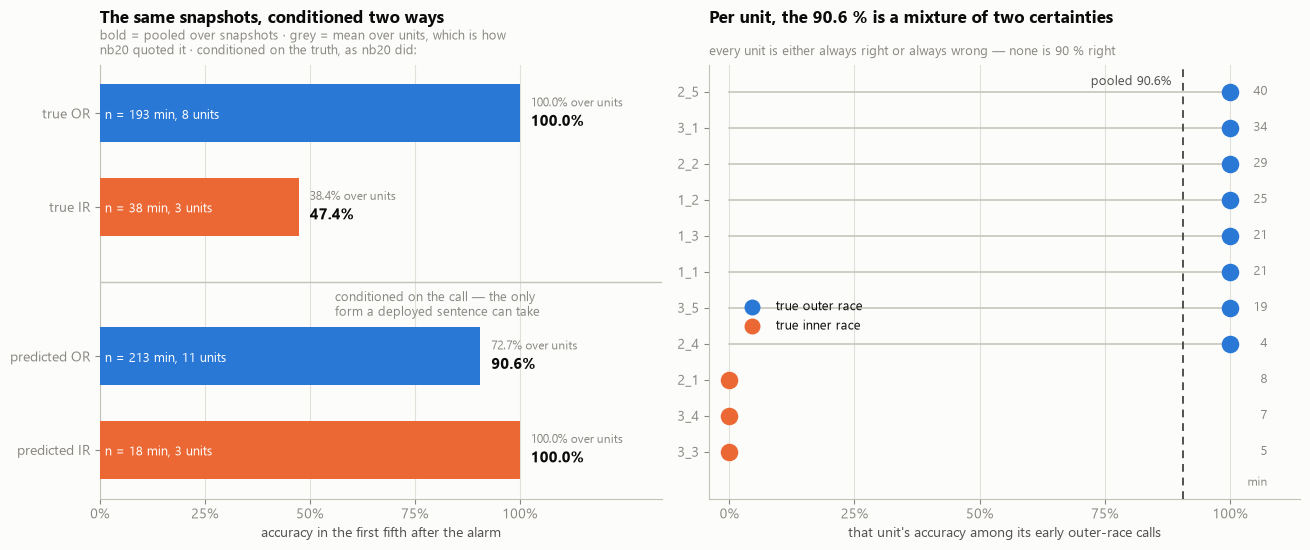

early outer-race calls: 213 over 11 units, 20 wrong (9.4%)
  true element of those errors: {'IR': 20}
  contributed by: {'Bearing2_1': 8, 'Bearing3_4': 7, 'Bearing3_3': 5}

per-unit accuracy in that cell: 8 units at 100 %, 3 at 0 %, 0 in between
  pooled over snapshots 90.6%   mean over units 72.7%   between-unit sd 0.467

for reference, nb20's conditioning (true IR, first fifth): 38.4% mean over units, 47.4% pooled   (nb20 reported 38.4 %)


In [2]:
early = T[T["fbin"] == 0]
GROUPS = [("true OR", early[early["truth"] == "OR"], C_BLUE),
          ("true IR", early[early["truth"] == "IR"], C_ORANGE),
          ("predicted OR", early[early["pred"] == "OR"], C_BLUE),
          ("predicted IR", early[early["pred"] == "IR"], C_ORANGE)]

fig, (axa, axb) = plt.subplots(1, 2, figsize=(13.2, 5.6),
                               gridspec_kw=dict(width_ratios=[1, 1.05]))

ypos = [0, 1, 2.6, 3.6]                       # the gap separates the two conditionings
for y, (nm, s, col) in zip(ypos, GROUPS):
    v, um = s["ok"].mean(), s.groupby("Bearing")["ok"].mean().mean()
    axa.barh(y, v, height=0.62, color=col, zorder=3)
    axa.annotate(f"{v:.1%}", (v, y), xytext=(8, -9), textcoords="offset points",
                 color=INK, fontsize=11, fontweight="bold")
    axa.annotate(f"{um:.1%} over units", (v, y), xytext=(8, 5),
                 textcoords="offset points", color=MUTED, fontsize=8.4)
    axa.annotate(f"n = {len(s)} min, {s['Bearing'].nunique()} units", (0.012, y),
                 xytext=(0, -4), textcoords="offset points",
                 color="white" if v > 0.45 else INK2, fontsize=9.0)
axa.set_yticks(ypos)
axa.set_yticklabels([g[0] for g in GROUPS])
axa.invert_yaxis()
axa.set_xlim(0, 1.34)
axa.set_xticks(np.arange(0, 1.01, 0.25))
axa.set_xticklabels([f"{v:.0%}" for v in np.arange(0, 1.01, 0.25)])
axa.set_xlabel("accuracy in the first fifth after the alarm")
axa.set_title("The same snapshots, conditioned two ways", loc="left", fontsize=12.5,
              fontweight="bold", pad=30)
axa.annotate("bold = pooled over snapshots · grey = mean over units, which is how\n"
             "nb20 quoted it · conditioned on the truth, as nb20 did:", xy=(0, 1.015),
             xycoords="axes fraction", fontsize=9.3, color=MUTED, va="bottom")
axa.axhline(1.8, color=BASE, lw=1.0, zorder=2)
axa.annotate("conditioned on the call — the only\nform a deployed sentence can take",
             xy=(0.56, 2.05), fontsize=9.3, color=MUTED, va="center")
axa.grid(axis="y", visible=False)

cell = early[early["pred"] == "OR"]
per = cell.groupby("Bearing").agg(acc=("ok", "mean"), n=("ok", "size"),
                                  truth=("truth", "first")).sort_values(["acc", "n"])
for i, (b, r) in enumerate(per.iterrows()):
    axb.plot([0, r["acc"]], [i, i], color=BASE, lw=1.1, zorder=2)
    axb.scatter([r["acc"]], [i], s=135, color=FCOLOR[r["truth"]], zorder=4)
    axb.annotate(f"{r['n']:>3d}", (1.075, i), fontsize=9, color=MUTED, va="center",
                 ha="right")
axb.axvline(cell["ok"].mean(), color=INK2, lw=1.4, ls=(0, (4, 3)), zorder=5)
axb.annotate(f"pooled {cell['ok'].mean():.1%}", (cell["ok"].mean(), len(per) - 0.72),
             xytext=(-8, 0), textcoords="offset points", fontsize=9.5, color=INK2,
             ha="right", va="center")
axb.set_ylim(-1.3, len(per) - 0.25)
axb.set_yticks(range(len(per)))
axb.set_yticklabels([b.replace("Bearing", "") for b in per.index])
axb.set_xlim(-0.04, 1.14)
axb.set_xticks(np.arange(0, 1.01, 0.25))
axb.set_xticklabels([f"{v:.0%}" for v in np.arange(0, 1.01, 0.25)])
axb.set_xlabel("that unit's accuracy among its early outer-race calls")
axb.set_title("Per unit, the 90.6 % is a mixture of two certainties", loc="left",
              fontsize=12.5, fontweight="bold", pad=30)
axb.annotate("every unit is either always right or always wrong — none is 90 % right",
             xy=(0, 1.015), xycoords="axes fraction", fontsize=9.3, color=MUTED,
             va="bottom")
for lab, col in (("true outer race", C_BLUE), ("true inner race", C_ORANGE)):
    axb.scatter([], [], s=110, color=col, label=lab)
axb.legend(loc="center left", fontsize=9.5, bbox_to_anchor=(0.03, 0.42))
axb.annotate("min", (1.075, -0.85), fontsize=8.5, color=MUTED, va="center", ha="right")
axb.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

wrong = early[(early["pred"] == "OR") & (~early["ok"])]
print(f"early outer-race calls: {len(cell)} over {cell['Bearing'].nunique()} units, "
      f"{(~cell['ok']).sum()} wrong ({1 - cell['ok'].mean():.1%})")
print(f"  true element of those errors: {wrong['truth'].value_counts().to_dict()}")
print(f"  contributed by: {wrong['Bearing'].value_counts().to_dict()}")
u = per["acc"]
print(f"\nper-unit accuracy in that cell: {(u == 1).sum()} units at 100 %, "
      f"{(u == 0).sum()} at 0 %, {((u > 0) & (u < 1)).sum()} in between")
print(f"  pooled over snapshots {cell['ok'].mean():.1%}   "
      f"mean over units {u.mean():.1%}   between-unit sd {u.std():.3f}")
tri = T[(T["truth"] == "IR") & (T["fbin"] == 0)]
print(f"\nfor reference, nb20's conditioning (true IR, first fifth): "
      f"{tri.groupby('Bearing')['ok'].mean().mean():.1%} mean over units, "
      f"{tri['ok'].mean():.1%} pooled   (nb20 reported 38.4 %)")

The sentence cannot be said, because the class it is about is not the class that gets called. Conditioned on the truth, first-fifth inner race sits at 38.4 % averaged over its three units (the number nb20 reported, reproduced exactly), or 47.4 % pooled over snapshots. The two differ because those units contribute 9, 8 and 21 minutes apiece. Conditioned on the prediction, first-fifth inner-race calls are right 18 times out of 18. The proposed sentence would attach a 60 % error rate to the one early call this system never gets wrong.

The error has moved to the other branch. All 20 wrong early calls are inner-race bearings called outer race, contributed by all three inner-race units (2_1: 8, 3_4: 7, 3_3: 5). So the deployable sentence is about outer-race calls: early outer-race calls are wrong 9.4 % of the time, and every one of those errors is a missed inner race.

That sentence is true, but it still misleads, as the right panel shows. Eight units are right through 100 % of their early window and three are wrong through 100 % of theirs. No unit is anywhere near 90 %. The pooled rate is a mixing proportion between two certainties, not a frequency any bearing experiences, and what decides which of the two a machine is in is the quantity the system cannot observe.

The two framings also differ in precision. Read per snapshot, 20 errors in 213 gives 9.4 % with a binomial interval of [6.3 %, 13.4 %], but the 20 errors come from 3 bearings, so that interval is an artefact of counting correlated minutes as independent trials. Read per unit, 3 of 11 gives 27.3 % with a Clopper–Pearson interval of [7.9 %, 56.4 %]. The wide interval is the one to quote, and it is an interval over units.

## Between-unit interval on the early outer-race rate

If the layer is going to quote a rate, it has to quote it before seeing the unit. The next cell does what a deployment would do: it estimates the cell's rate from the ten training units, through models that never saw the eleventh, and carries the between-unit spread as an interval, since that spread is the only evidence available about how far the rate travels.

The interval is the deliverable, not the point estimate. A rate quoted without one asserts a precision that eleven bearings cannot support.

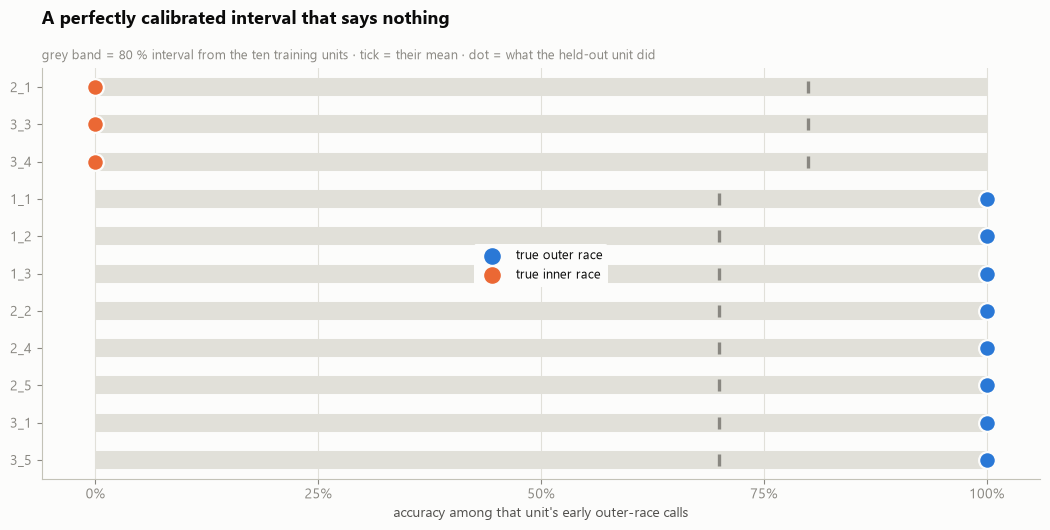

unit       true   stated      80 % interval  realised  covered
2_1        IR      80.0% [  0.0%,100.0%]      0.0%  True
3_3        IR      80.0% [  0.0%,100.0%]      0.0%  True
3_4        IR      80.0% [  0.0%,100.0%]      0.0%  True
1_1        OR      70.0% [  0.0%,100.0%]    100.0%  True
1_2        OR      70.0% [  0.0%,100.0%]    100.0%  True
1_3        OR      70.0% [  0.0%,100.0%]    100.0%  True
2_2        OR      70.0% [  0.0%,100.0%]    100.0%  True
2_4        OR      70.0% [  0.0%,100.0%]    100.0%  True
2_5        OR      70.0% [  0.0%,100.0%]    100.0%  True
3_1        OR      70.0% [  0.0%,100.0%]    100.0%  True
3_5        OR      70.0% [  0.0%,100.0%]    100.0%  True

80 % interval covers 11/11 held-out units
  its width is 100%-100% on every fold

the same fact, per unit: 3/11 = 27.3% of units misdiagnosed through their whole early window
  Clopper-Pearson 90 % CI [7.9%, 56.4%]
the same fact, per snapshot: 20/213 = 9.4%, binomial 90 % CI [6.3%, 13.4%]  <- correlated minu

In [3]:
def early_or_rate(preds, b):
    '''That unit's accuracy among its early outer-race calls.'''
    p, _ = preds[b]
    n = len(p)
    sel = ((np.arange(n) / n * NB).astype(int) == 0) & (p == "OR")
    return (p[sel] == FAULT[b]).mean() if sel.any() else np.nan


rows = []
for h in RACE:
    tr = [early_or_rate({u: NESTED[(h, u)]}, u) for u in RACE if u != h]
    tr = [v for v in tr if v == v]
    lo, hi = np.quantile(tr, [0.10, 0.90])
    rows.append(dict(Bearing=h, truth=FAULT[h], stated=float(np.mean(tr)),
                     lo=float(lo), hi=float(hi), realised=early_or_rate(OUTER, h)))
IV = pd.DataFrame(rows)
IV["covered"] = (IV["lo"] <= IV["realised"]) & (IV["realised"] <= IV["hi"])

fig, ax = plt.subplots(figsize=(10.6, 5.4))
order = IV.sort_values(["truth", "Bearing"]).reset_index(drop=True)
for i, r in order.iterrows():
    ax.plot([r["lo"], r["hi"]], [i, i], color=GRID, lw=13, solid_capstyle="butt", zorder=2)
    ax.scatter([r["stated"]], [i], s=70, color=MUTED, marker="|", linewidths=2.4, zorder=4)
    ax.scatter([r["realised"]], [i], s=145, color=FCOLOR[r["truth"]], zorder=5,
               edgecolor=SURFACE, linewidth=1.6)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([b.replace("Bearing", "") for b in order["Bearing"]])
ax.invert_yaxis()
ax.set_xlim(-0.06, 1.06)
ax.set_xticks(np.arange(0, 1.01, 0.25))
ax.set_xticklabels([f"{v:.0%}" for v in np.arange(0, 1.01, 0.25)])
ax.set_xlabel("accuracy among that unit's early outer-race calls")
ax.set_title("A perfectly calibrated interval that says nothing", loc="left",
             fontsize=13, fontweight="bold", pad=32)
ax.annotate("grey band = 80 % interval from the ten training units · tick = their mean · "
            "dot = what the held-out unit did", xy=(0, 1.015), xycoords="axes fraction",
            fontsize=9.3, color=MUTED, va="bottom")
for lab, col in (("true outer race", C_BLUE), ("true inner race", C_ORANGE)):
    ax.scatter([], [], s=120, color=col, label=lab)
ax.legend(loc="center", fontsize=9.5, bbox_to_anchor=(0.5, 0.52), frameon=True,
          facecolor=SURFACE, edgecolor="none", framealpha=1.0)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(f"{'unit':10s} {'true':5s} {'stated':>7} {'80 % interval':>18} {'realised':>9}  covered")
for _, r in order.iterrows():
    print(f"{r['Bearing'].replace('Bearing', ''):10s} {r['truth']:5s} {r['stated']:7.1%} "
          f"[{r['lo']:6.1%},{r['hi']:6.1%}] {r['realised']:9.1%}  {bool(r['covered'])}")
print(f"\n80 % interval covers {int(IV['covered'].sum())}/{len(IV)} held-out units")
print(f"  its width is {IV['hi'].sub(IV['lo']).min():.0%}-{IV['hi'].sub(IV['lo']).max():.0%} "
      f"on every fold")
k, n = 3, 11
print(f"\nthe same fact, per unit: {k}/{n} = {k / n:.1%} of units misdiagnosed through "
      f"their whole early window")
print(f"  Clopper-Pearson 90 % CI [{beta.ppf(0.05, k, n - k + 1):.1%}, "
      f"{beta.ppf(0.95, k + 1, n - k):.1%}]")
kk, nn = int((~cell["ok"]).sum()), len(cell)
print(f"the same fact, per snapshot: {kk}/{nn} = {kk / nn:.1%}, "
      f"binomial 90 % CI [{beta.ppf(0.05, kk, nn - kk + 1):.1%}, "
      f"{beta.ppf(0.95, kk + 1, nn - kk):.1%}]  <- correlated minutes, not trials")
# Cached so build_registry.py can recompute the per-unit early-call claim
IV.to_csv(OUT / "xjtu_reliability_intervals.csv", index=False)
cell.to_csv(OUT / "xjtu_reliability_snapshots.csv", index=False)
print("wrote xjtu_reliability_intervals.csv, xjtu_reliability_snapshots.csv")


The interval covers 11 of 11 held-out units and is [0 %, 100 %] on every one of them. It is as well calibrated as a claim can be and carries no information. With eight units at 100 % and three at 0 %, any 80 % interval over the training units must span the full range, because that is where the next unit could land.

The point estimate behaves oddly. The stated rate is 70.0 % on every fold that holds out an outer-race unit and 80.0 % on each of the three that hold out an inner-race one, so it is highest for the units about to be misdiagnosed. The cause is in how the table is built: withholding an inner-race unit removes one of only three examples of this failure mode from the reliability table, so the table becomes more optimistic just as the failure it is meant to warn about becomes more likely. With three minority units, leave-one-out deletes a third of the evidence for the failure it is estimating.

## Information in the phase key and its availability in deployment

The two findings above are about one cell. The layer as a whole is a keyed table, and two checks decide whether it is worth shipping.

The first check is whether the phase key carries information. Calibration alone cannot answer that, because a table keyed on noise is perfectly calibrated at the parent rate. So each scheme is scored on three things at once: calibration error against held-out units, discrimination (whether the stated rate ranks right calls above wrong ones), and resolution (whether it varies at all). Two controls fix the reference: the phase labels permuted within each unit, and a matched random key with the same number of bins in the same position, which isolates the phase key from the element key it sits beside.

The second check is whether a deployment has such a key. `fbin` bins the share of post-alarm life elapsed, which needs the failure time and is therefore available only in hindsight, so every notebook that has said "first fifth" has used a retrospective coordinate. `mbin` bins elapsed minutes, which is what a running system holds. Post-alarm windows here span 17 to 199 minutes, so the two keys are not close to each other, and the difference between them is the loss from using a key that can be deployed.

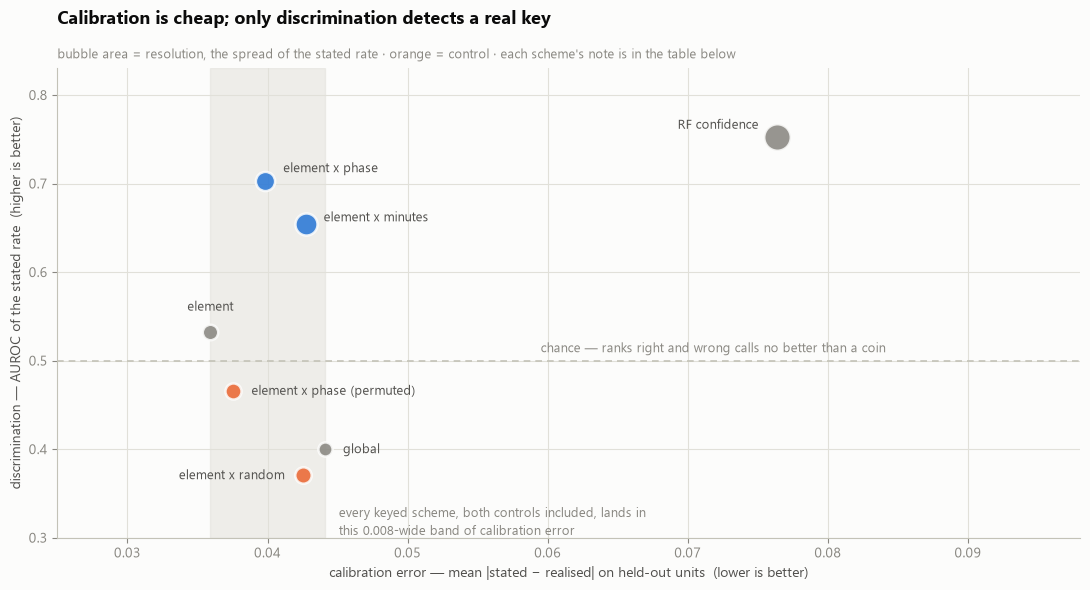

                    scheme                                   note   MAE  AUROC  resolution
                    global                          no key at all 0.044  0.400       0.006
                   element                 predicted element only 0.036  0.533       0.013
           element x phase + share of post-alarm life (hindsight) 0.040  0.703       0.039
         element x minutes     + minutes since alarm (deployable) 0.043  0.654       0.063
          element x random     control: matched random second key 0.043  0.371       0.020
             RF confidence          the nb15 flag, for comparison 0.076  0.752       0.106
element x phase (permuted)         control: phase labels shuffled 0.038  0.466       0.017

cell occupancy, share-of-life key: {('IR', 0): 18, ('IR', 1): 37, ('IR', 2): 40, ('IR', 3): 37, ('IR', 4): 36, ('OR', 0): 213, ('OR', 1): 189, ('OR', 2): 187, ('OR', 3): 189, ('OR', 4): 185}
cell occupancy, minutes key:       {('IR', 0): 14, ('IR', 1): 29, ('IR', 2): 28,

In [4]:
SCHEMES = [("global", None, "no key at all"),
           ("element", None, "predicted element only"),
           ("element x phase", "fbin", "+ share of post-alarm life (hindsight)"),
           ("element x minutes", "mbin", "+ minutes since alarm (deployable)"),
           ("element x random", "rbin", "control: matched random second key")]
M = 10.0                                  # shrinkage pseudo-count toward the parent rate


def stated(TR, r, scheme, key):
    par = TR["ok"].mean()
    if scheme == "global":
        return par
    sub = TR[TR["pred"] == r["pred"]]
    if key is not None:
        sub = sub[sub[key] == r[key]]
    if not len(sub):
        return par
    return float((sub["ok"].sum() + M * par) / (len(sub) + M))


def run(permute):
    rec = []
    for h in RACE:
        others = [u for u in RACE if u != h]
        TR = long({u: NESTED[(h, u)] for u in others}, others, permute_phase=permute)
        TE = long({h: OUTER[h]}, [h], permute_phase=permute)
        for _, r in TE.iterrows():
            row = dict(Bearing=h, truth=r["truth"], pred=r["pred"], ok=r["ok"],
                       conf=r["conf"])
            for nm, key, _ in SCHEMES:
                row[nm] = stated(TR, r, nm, key)
            rec.append(row)
    return pd.DataFrame(rec)


R, RP = run(False), run(True)


def measure(df, col):
    '''Calibration is snapshot-weighted because the claim is a per-snapshot rate.'''
    g = df.groupby(["Bearing", pd.cut(df[col], np.linspace(0, 1, 11), include_lowest=True)],
                   observed=True).agg(st=(col, "mean"), re=("ok", "mean"), n=("ok", "size"))
    w = g["n"] / g["n"].sum()
    return (float((w * (g["st"] - g["re"]).abs()).sum()),
            float(roc_auc_score(df["ok"].astype(int), df[col])),
            float(df[col].std()))


ROWS = [(nm, note, *measure(R, nm)) for nm, _, note in SCHEMES]
ROWS.append(("RF confidence", "the nb15 flag, for comparison", *measure(R, "conf")))
ROWS.append(("element x phase (permuted)", "control: phase labels shuffled",
             *measure(RP, "element x phase")))
S = pd.DataFrame(ROWS, columns=["scheme", "note", "MAE", "AUROC", "resolution"])

fig, ax = plt.subplots(figsize=(11.0, 6.0))
IS_CTL = S["note"].str.startswith("control")
COL = [C_ORANGE if c else (C_BLUE if "x " in s and "random" not in s else MUTED)
       for s, c in zip(S["scheme"], IS_CTL)]
OFFSET = {"global": (13, -3, "left"), "element": (0, 15, "center"),
          "element x phase": (13, 6, "left"), "element x minutes": (13, 2, "left"),
          "element x random": (-13, -3, "right"), "RF confidence": (-13, 6, "right"),
          "element x phase (permuted)": (13, -3, "left")}
keyed = S[S["scheme"] != "RF confidence"]
ax.axvspan(keyed["MAE"].min(), keyed["MAE"].max(), color=GRID, alpha=0.5, zorder=1)
ax.annotate(f"every keyed scheme, both controls included, lands in\nthis "
            f"{keyed['MAE'].max() - keyed['MAE'].min():.3f}-wide band of calibration error",
            (keyed["MAE"].max(), 0.318), xytext=(10, 0), textcoords="offset points",
            fontsize=9.0, color=MUTED, va="center", linespacing=1.4)
ax.axhline(0.5, color=BASE, lw=1.2, ls=(0, (4, 3)), zorder=2)
ax.annotate("chance — ranks right and wrong calls no better than a coin", (0.0595, 0.5),
            xytext=(0, 6), textcoords="offset points", fontsize=9, color=MUTED)
for (_, r), c in zip(S.iterrows(), COL):
    ax.scatter([r["MAE"]], [r["AUROC"]], s=90 + 2600 * r["resolution"], color=c,
               alpha=0.88, zorder=4, edgecolor=SURFACE, linewidth=1.8)
    dx, dy, ha = OFFSET[r["scheme"]]
    ax.annotate(r["scheme"], (r["MAE"], r["AUROC"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=9.4, color=INK2, ha=ha)
ax.set_xlim(0.025, 0.098)
ax.set_ylim(0.30, 0.83)
ax.set_xlabel("calibration error — mean |stated − realised| on held-out units  (lower is better)")
ax.set_ylabel("discrimination — AUROC of the stated rate  (higher is better)")
ax.set_title("Calibration is cheap; only discrimination detects a real key", loc="left",
             fontsize=13, fontweight="bold", pad=32)
ax.annotate("bubble area = resolution, the spread of the stated rate · orange = control "
            "· each scheme's note is in the table below",
            xy=(0, 1.015), xycoords="axes fraction", fontsize=9.3, color=MUTED, va="bottom")
plt.tight_layout()
plt.show()

print(S.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print(f"\ncell occupancy, share-of-life key: "
      f"{T.groupby(['pred', 'fbin']).size().to_dict()}")
print(f"cell occupancy, minutes key:       "
      f"{T.groupby(['pred', 'mbin']).size().to_dict()}")
# Cached so build_registry.py can recompute the calibration-vs-discrimination claim
S.to_csv(OUT / "xjtu_reliability_schemes.csv", index=False)
print("wrote xjtu_reliability_schemes.csv")


The phase key carries information, and it is the retrospective one that is sharp. Keying on the predicted element alone reaches 0.533 AUROC, which is close to nothing. Adding the share-of-post-alarm-life bin lifts it to 0.703, while the matched random second key, identical in structure, falls to 0.371, and permuting the phase labels reduces it to 0.466. Both controls behave as controls should, so the lift comes from the phase key and not from the shape of the table.

Calibration does not register any of this. Permuting the phase labels leaves the calibration error at 0.038 against the true key's 0.040, so the shuffled control is better calibrated than the real key, while discrimination falls by 24 points. Every keyed scheme in the table, both controls included, sits inside a band 0.008 wide (0.036 to 0.044) while AUROC ranges over 0.33. The best-calibrated of them is `element`, at 0.036, which discriminates at 0.533, which is nothing. This is the methodological result of the notebook: a reliability layer reported by its calibration alone cannot be told apart from one keyed on noise, and every such number in this project's paper has to carry discrimination and resolution beside it.

Using a deployable key loses about a third of the lift. Moving from the hindsight key to minutes-since-alarm takes AUROC from 0.703 to 0.654, still well clear of both controls, so a running system can carry a usefully keyed table. The loss comes from the occupancy line: with post-alarm windows spanning 17 to 199 minutes, a fixed 10-minute bin covers a whole unit's first three fifths and only a twentieth of another's, and the open-ended final bin absorbs 649 of the 963 outer-race snapshots. The minutes key has more spread than the hindsight key (resolution 0.063 against 0.039) and less discrimination, which points to unbalanced bins and not to informative ones.

One number here is not new. The RF confidence reaches 0.752, the highest in the table, the same 0.752 that notebook 15 measured and notebook 17 took apart. It is the best-discriminating column and remains unusable for this purpose, because nb17 showed that its discrimination comes from an inner-race detector and not from an error detector: within inner race the same score runs at 0.384, below chance.

## What the system can say

Notebook 17 set out to fix the output contract and left the per-element rate as the unit of output. This notebook took the next step that the notes specified and found that the step cannot be taken as written. The reason is worth carrying into the paper: a rate can be stated only if it is conditioned on something the speaker has.

What survives is smaller and firmer than the proposed sentence. When this system calls outer race in the first fifth after an alarm, the bearing is an undetected inner race in roughly 3 cases out of 11. With eleven units of evidence, that is somewhere between 1 in 13 and 1 in 2. Which case a given machine is in cannot be told from the vibration, and the system will not hesitate before getting it wrong.

That is a statement about units and carries its own width. It names the direction of the error and warns that confidence will not track it. It is deliverable today and needs no new signal processing, which is what the notes asked for. It says less than they expected, and about the other class.

### Findings

1. The specified sentence conditions on a quantity the system does not have. nb20's 38.4 % is conditioned on the true element; a deployed layer conditions on the predicted one. Under the deployable conditioning the same snapshots give 18/18 correct for early inner-race calls, so the proposed sentence would attach a 60 % error rate to the one early call the system never gets wrong.
2. The error moves to the other class. All 20 wrong early calls are inner-race bearings called outer race, from all three inner-race units. The deployable sentence is about outer-race calls, at 9.4 % wrong.
3. That 9.4 % describes no bearing. Eight units are right through their entire early window and three are wrong through theirs; none is in between. The pooled rate is a mixing proportion between two certainties.
4. The interval on it is [0 %, 100 %]. The 80 % between-unit interval covers 11/11 held-out units and spans the full range on every fold: perfectly calibrated, no information. Per unit the same fact reads 3/11 = 27.3 % with a Clopper–Pearson 90 % CI of [7.9 %, 56.4 %]; the per-snapshot 9.4 % [6.3 %, 13.4 %] is false precision from counting correlated minutes as trials.
5. Leave-one-out reliability is most optimistic where it fails. The stated rate is 80.0 % on each of the three inner-race folds against 70.0 % on all eight outer-race ones, because withholding a minority unit also withholds a third of the evidence for the failure mode being estimated.
6. The phase key carries information, and both controls confirm it. Element alone 0.533 AUROC, + phase 0.703, matched random second key 0.371, permuted phase 0.466.
7. Calibration cannot detect a dead key. Permuting the phase labels changes calibration error by 0.002, in the favourable direction, while discrimination falls 24 points. All six keyed schemes sit inside a 0.008-wide band of calibration error while AUROC ranges over 0.33. Reliability numbers must be reported with discrimination and resolution, or they cannot be falsified.
8. "First fifth" is a retrospective coordinate. It needs the failure time. The deployable key, minutes since alarm, holds 0.654 AUROC, clear of both controls, so the layer ships, but the 17-to-199-minute spread of post-alarm windows means fixed bins are unbalanced and not informative.